# Exploratory Data Analysis: UCI Adult Income Dataset

**Goal:** Perform a thorough exploratory data analysis (EDA) on the UCI Adult dataset.

The dataset contains census-related information used to study whether a person's annual income is above or below \$50K. 

**Dataset source:** UCI Machine Learning Repository — Adult / Census Income dataset.


In [92]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)


## 1. Load the dataset

In [93]:
url = "adult.data"

columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

df.head()


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Basic inspection

In [94]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())


Shape: (32561, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Data types:
age               int64
workclass           str
fnlwgt            int64
education           str
education-num     int64
marital-status      str
occupation          str
relationship        str
race                str
sex                 str
capital-gain      int64
capital-loss      int64
hours-per-week    int64
native-country      str
income              str
dtype: object

Missing values:
age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64


The dataset has 15 columns. Six are numerical and the remaining columns are categorical.  
For categorical variables, statistics such as mean and median are not meaningful, so frequency counts and modes are used instead.

In [95]:
numerical_cols = [
    "age",
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

categorical_cols = [col for col in df.columns if col not in numerical_cols]

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)


Numerical columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']


## 3. Numerical summary: min, max, mean, median, and outliers

In [96]:
summary = pd.DataFrame({
    "min": df[numerical_cols].min(),
    "max": df[numerical_cols].max(),
    "mean": df[numerical_cols].mean(),
    "median": df[numerical_cols].median()
})

summary


,min,max,mean,median
age,17,90,38.581647,37.0
fnlwgt,12285,1484705,189778.366512,178356.0
education-num,1,16,10.080679,10.0
capital-gain,0,99999,1077.648844,0.0
capital-loss,0,4356,87.303830,0.0
hours-per-week,1,99,40.437456,40.0


In [97]:
# Detect outliers using the 1.5 × IQR rule
outlier_summary = []

for col in numerical_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower) | (df[col] > upper)][col]

    outlier_summary.append({
        "variable": col,
        "Q1": q1,
        "Q3": q3,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": len(outliers)
    })

outlier_table = pd.DataFrame(outlier_summary)
outlier_table


,variable,Q1,Q3,lower_bound,upper_bound,outlier_count
0,age,28.0,48.0,-2.0,78.0,143
1,fnlwgt,117827.0,237051.0,-61009.0,415887.0,992
2,education-num,9.0,12.0,4.5,16.5,1198
3,capital-gain,0.0,0.0,0.0,0.0,2712
4,capital-loss,0.0,0.0,0.0,0.0,1519
5,hours-per-week,40.0,45.0,32.5,52.5,9008


The numerical variables have different ranges and distributions. Age ranges from 17 to 90, with a mean of about 38.58 and a median of 37. The final weight (fnlwgt) ranges from 12,285 to 1,484,705, with a mean of about 189,778 and a median of 178,356. Education level, represented numerically by education-num, ranges from 1 to 16 and has a mean of 10.08 and a median of 10. Capital gain and capital loss both have medians of 0, showing that most individuals have no recorded capital gain or loss. Hours worked per week ranges from 1 to 99, with a mean of about 40.44 and a median of 40 hours.

Using the 1.5 × IQR rule, possible outliers were found in all six numerical variables. There were 143 age outliers, 992 fnlwgt outliers, 1,198 education-num outliers, 2,712 capital-gain outliers, 1,519 capital-loss outliers, and 9,008 hours-per-week outliers. Capital gain and capital loss contain many zero values, so any positive value is flagged by the IQR method because both Q1 and Q3 are zero.

## 4. One-dimensional histograms for numerical variables

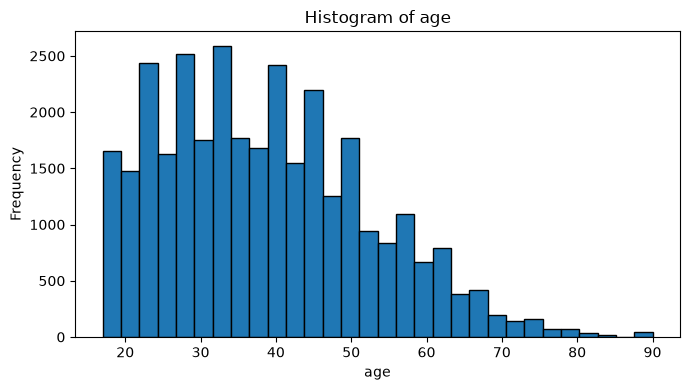

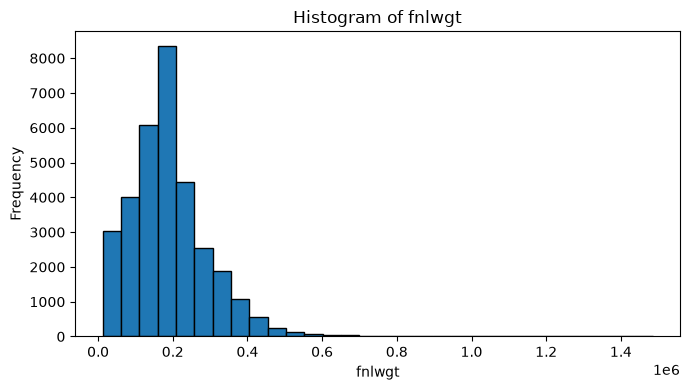

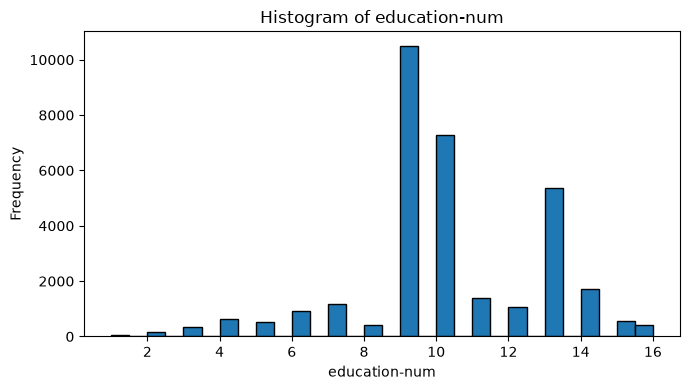

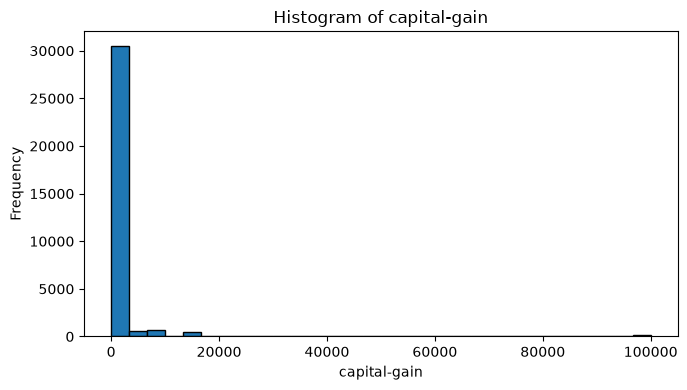

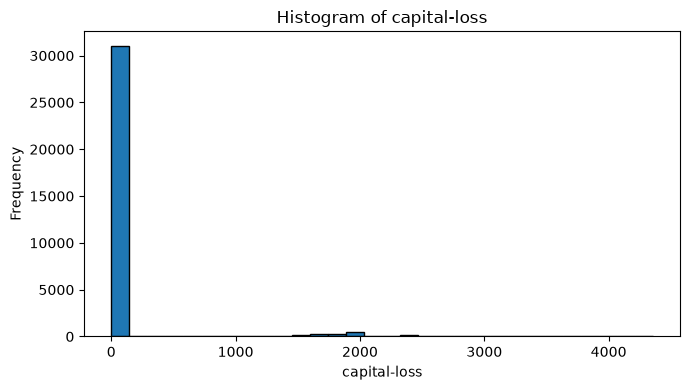

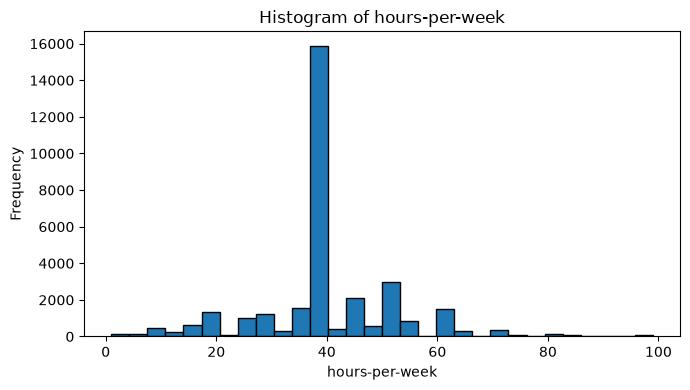

In [98]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col].dropna(), bins=30, edgecolor="black")
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 5. Bar charts for categorical variables

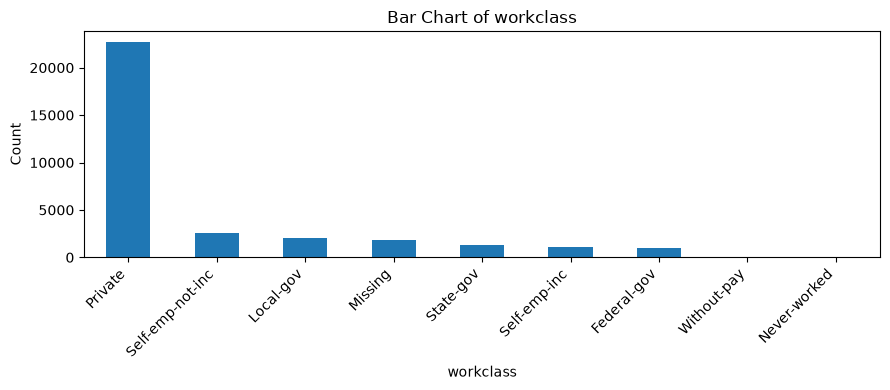

Most common value for workclass: Private (22696 rows)
Least common value for workclass: Never-worked (7 rows)



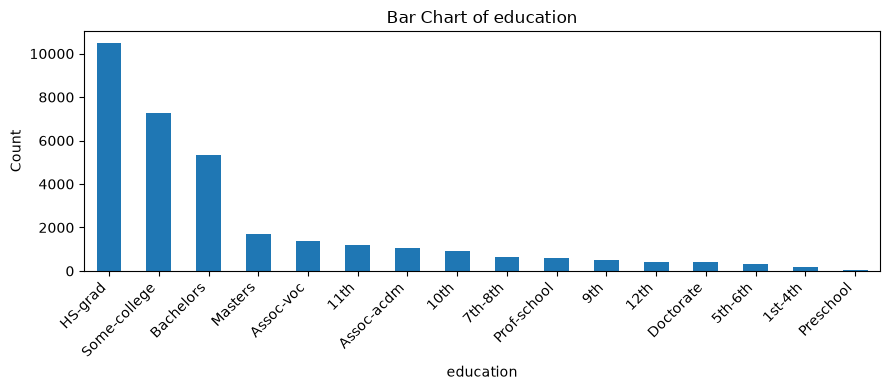

Most common value for education: HS-grad (10501 rows)
Least common value for education: Preschool (51 rows)



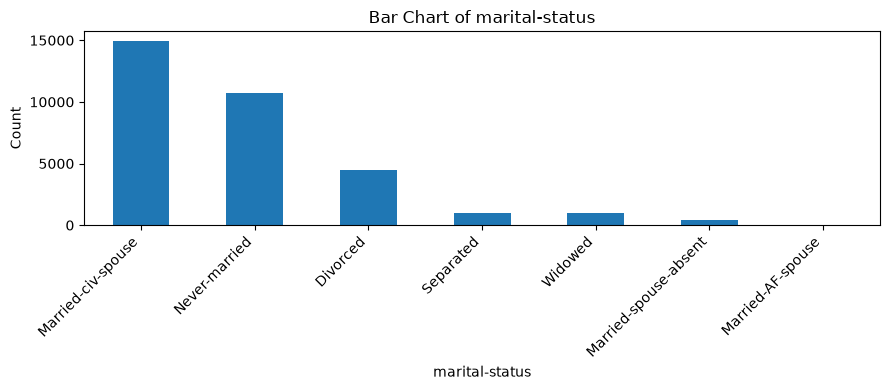

Most common value for marital-status: Married-civ-spouse (14976 rows)
Least common value for marital-status: Married-AF-spouse (23 rows)



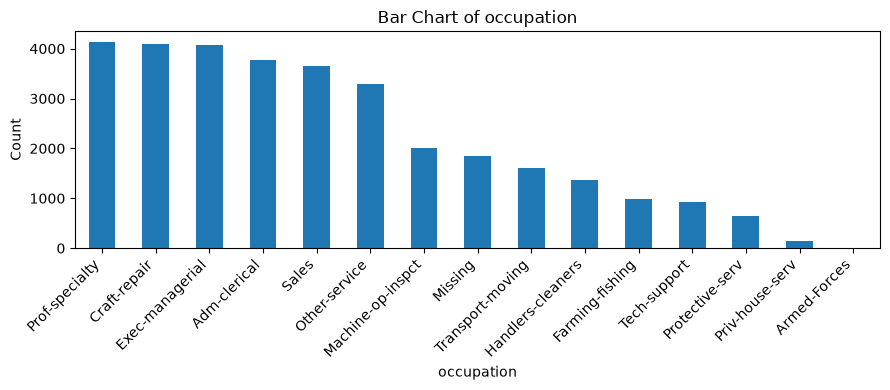

Most common value for occupation: Prof-specialty (4140 rows)
Least common value for occupation: Armed-Forces (9 rows)



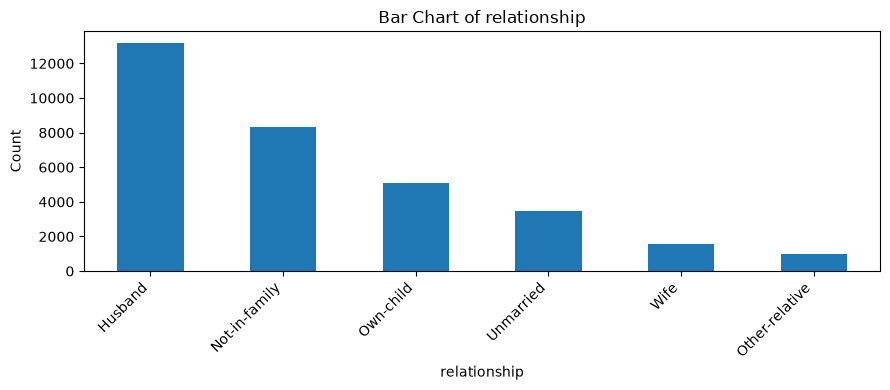

Most common value for relationship: Husband (13193 rows)
Least common value for relationship: Other-relative (981 rows)



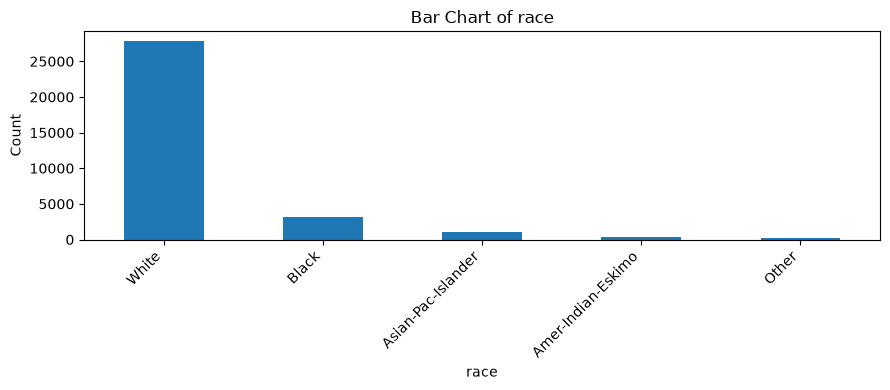

Most common value for race: White (27816 rows)
Least common value for race: Other (271 rows)



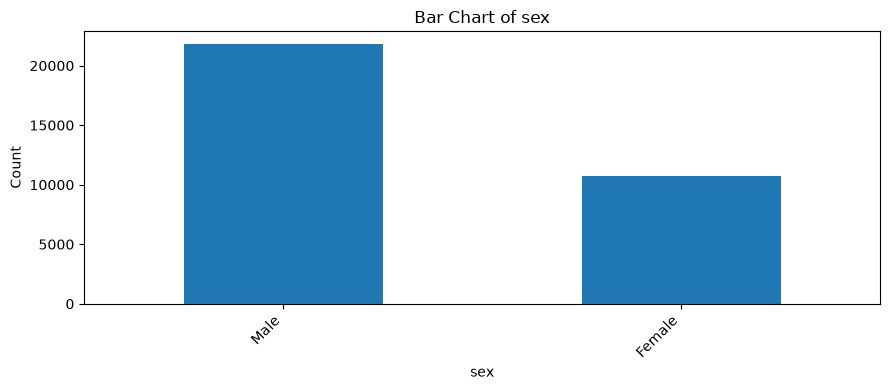

Most common value for sex: Male (21790 rows)
Least common value for sex: Female (10771 rows)



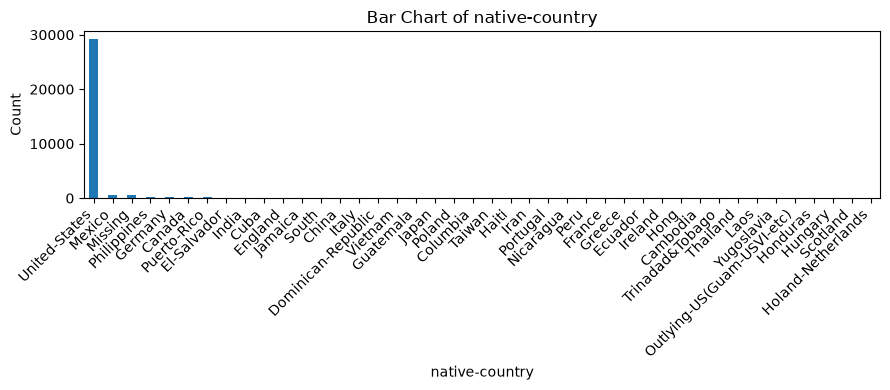

Most common value for native-country: United-States (29170 rows)
Least common value for native-country: Holand-Netherlands (1 rows)



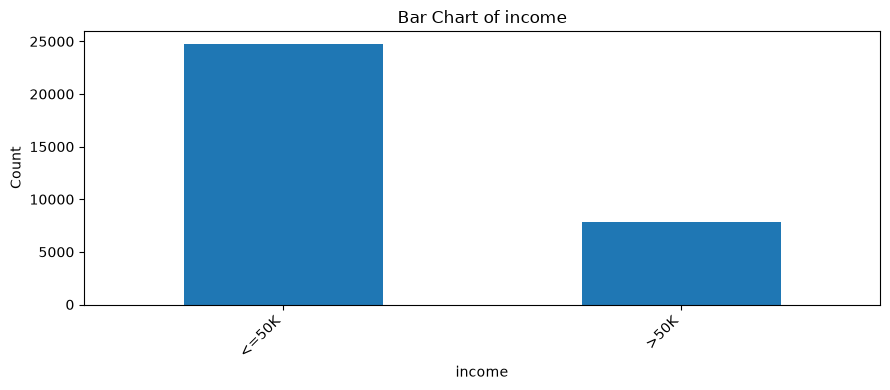

Most common value for income: <=50K (24720 rows)
Least common value for income: >50K (7841 rows)



In [99]:
for col in categorical_cols:
    counts = df[col].fillna("Missing").value_counts()

    plt.figure(figsize=(9, 4))
    counts.plot(kind="bar")
    plt.title(f"Bar Chart of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"Most common value for {col}: {counts.idxmax()} ({counts.max()} rows)")
    print(f"Least common value for {col}: {counts.idxmin()} ({counts.min()} rows)")
    print()


The categorical variables are not evenly distributed. Private is the most common workclass, HS-grad is the most common education level, White is the most common race, Male is the most common sex, and United-States is the most common native country. For income, 24,720 observations are <=50K, compared with 7,841 observations that are >50K.

## 6. All numerical variables in one box plot

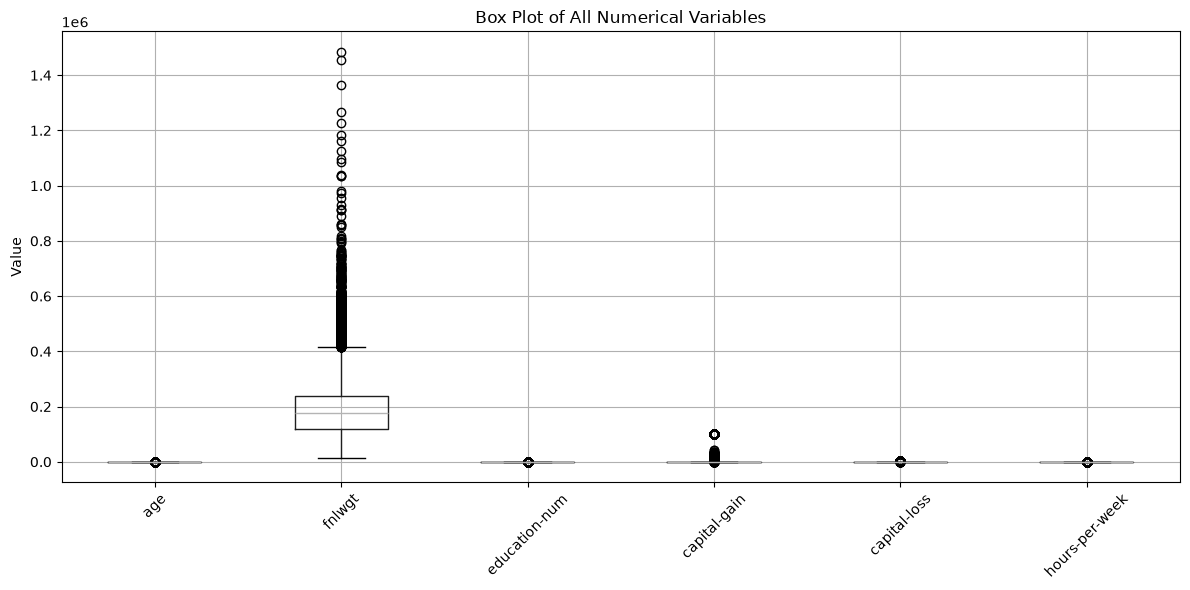

In [100]:
plt.figure(figsize=(12, 6))
df[numerical_cols].boxplot()
plt.title("Box Plot of All Numerical Variables")
plt.ylabel("Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 7. Pair-wise relationships: scatter-plot matrix

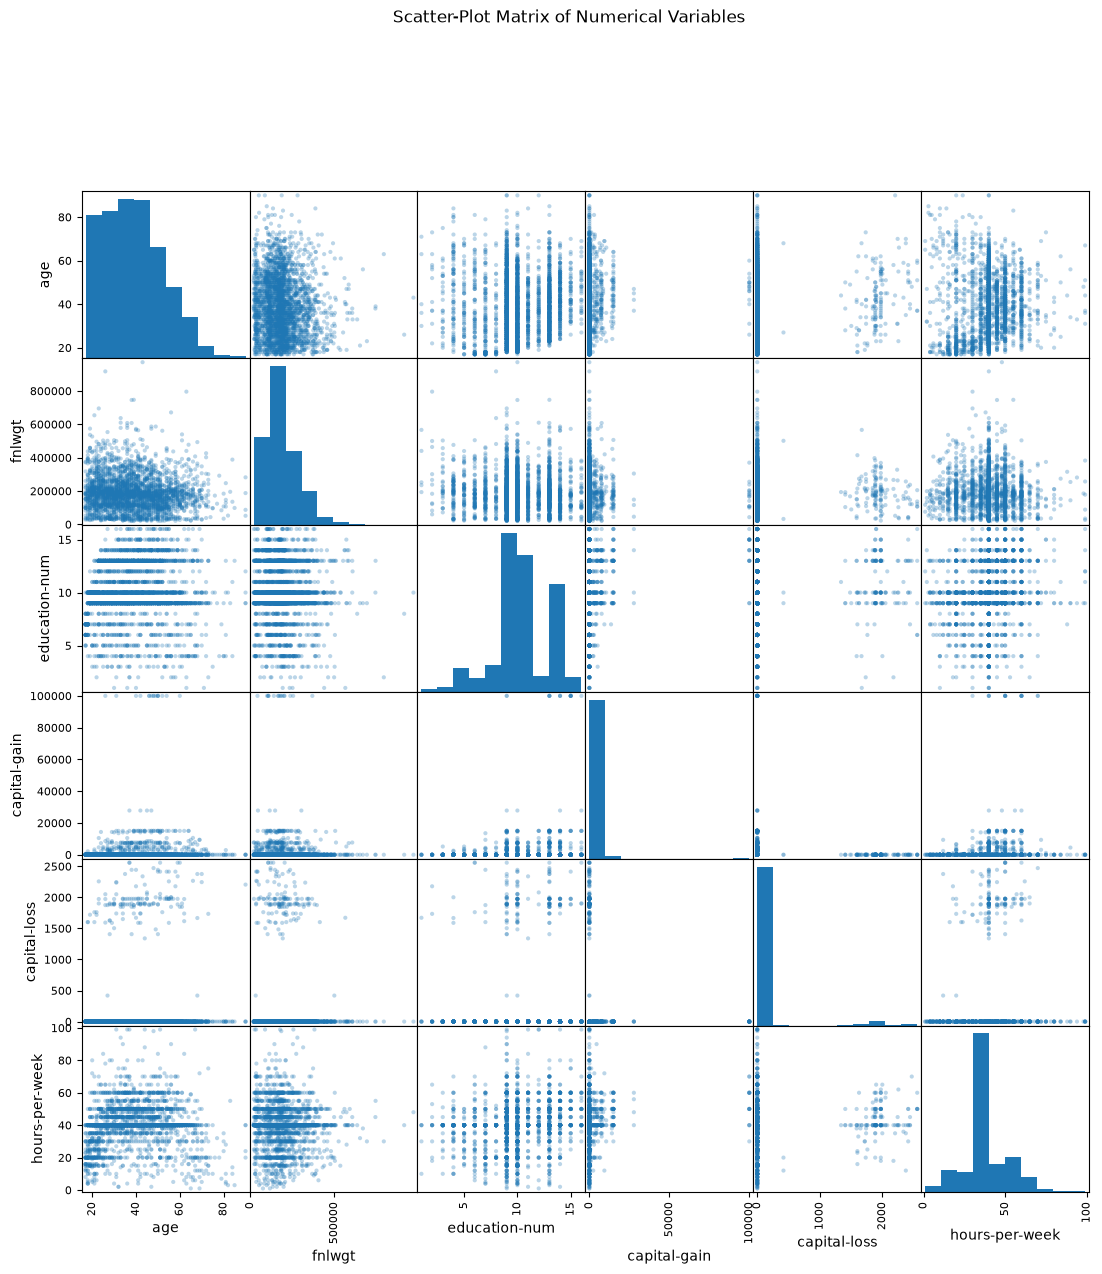

In [101]:
# A sample keeps the plot readable while preserving the overall relationships.
sample_size = min(3000, len(df))
sample_df = df[numerical_cols].dropna().sample(sample_size, random_state=42)

pd.plotting.scatter_matrix(
    sample_df,
    figsize=(13, 13),
    diagonal="hist",
    alpha=0.3
)

plt.suptitle("Scatter-Plot Matrix of Numerical Variables", y=1.02)
plt.show()


In [102]:
# Compare workclass with income using a cross-tabulation.
cat_table = pd.crosstab(df["workclass"], df["income"])
cat_table


income,<=50K,>50K
workclass,,
Federal-gov,589,371
Local-gov,1476,617
Never-worked,7,0
Private,17733,4963
Self-emp-inc,494,622
Self-emp-not-inc,1817,724
State-gov,945,353
Without-pay,14,0


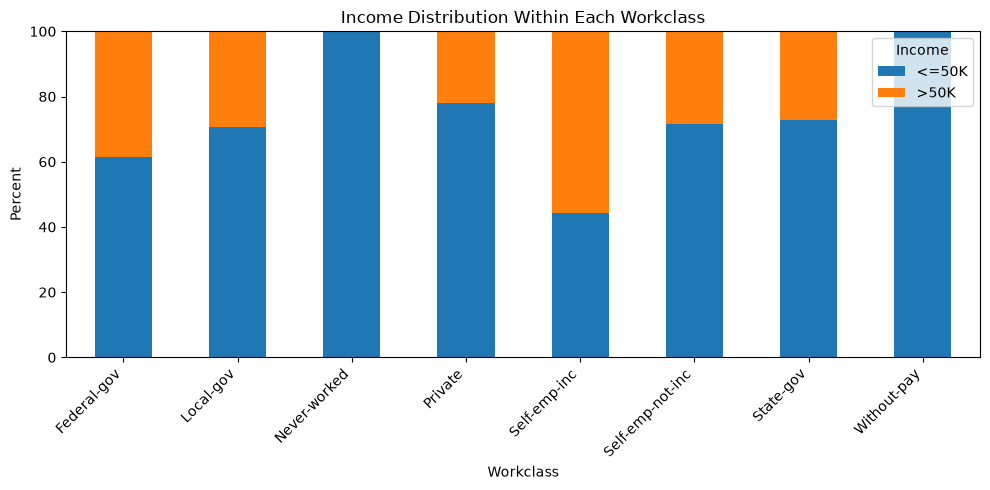

In [103]:
# Normalize by row so each workclass is shown as percentages.
cat_pct = pd.crosstab(
    df["workclass"],
    df["income"],
    normalize="index"
) * 100

cat_pct.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Income Distribution Within Each Workclass")
plt.xlabel("Workclass")
plt.ylabel("Percent")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()


The stacked bar chart compares workclass with income. The proportion of people earning >50K changes across different workclasses. For example, Self-emp-inc has a relatively high proportion of people earning >50K, while most people in the Private workclass earn <=50K.

## 9. Numerical vs. categorical

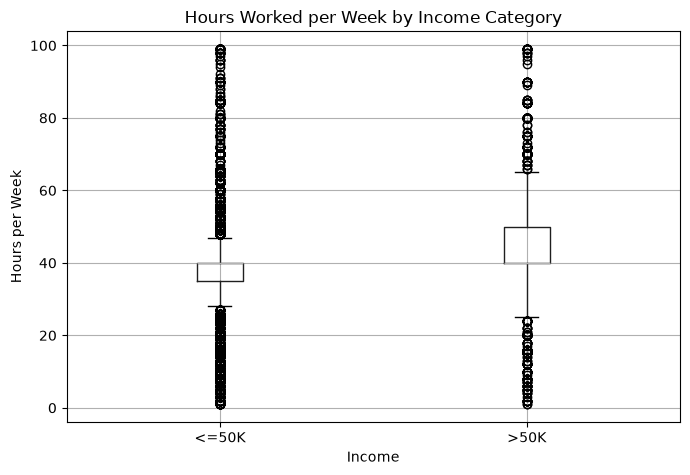

In [104]:
# Compare a numerical variable across a categorical variable.
df.boxplot(column="hours-per-week", by="income", figsize=(7, 5))
plt.title("Hours Worked per Week by Income Category")
plt.suptitle("")
plt.xlabel("Income")
plt.ylabel("Hours per Week")
plt.tight_layout()
plt.show()


The box plot compares hours worked per week across the two income categories. It allows us to compare the median, spread, and outliers in working hours for people earning <=50K and >50K.

## 10. Numerical relationships colored by a category

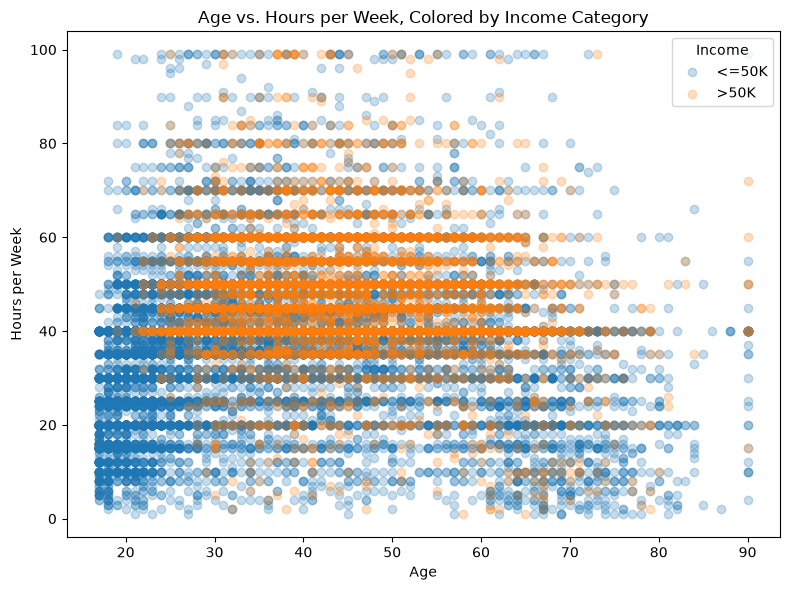

In [105]:
plot_df = df[["age", "hours-per-week", "income"]].dropna()

plt.figure(figsize=(8, 6))

for label in plot_df["income"].unique():
    subset = plot_df[plot_df["income"] == label]
    plt.scatter(
        subset["age"],
        subset["hours-per-week"],
        alpha=0.25,
        label=label
    )

plt.title("Age vs. Hours per Week, Colored by Income Category")
plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.legend(title="Income")
plt.tight_layout()
plt.show()


 This scatter plot compares age and hours worked per week, which are both numerical variables, while color represents the categorical income variable. Using color makes it possible to compare the two income groups within the same numerical relationship.